autorzy:Brojek

# Sentiment Analysis Using LSTM

# Load The Data

In [1]:
from urllib.request import urlretrieve
import zipfile

import nltk
import numpy as np
from keras import Input

amazon_mobile_reviews_url =  "https://eduds.blob.core.windows.net/nlp/Amazon_Unlocked_Mobile.csv.zip"
filename = "Amazon_Unlocked_Mobile.csv.zip"

urlretrieve(amazon_mobile_reviews_url, filename)

with zipfile.ZipFile("Amazon_Unlocked_Mobile.csv.zip") as zfile:
  zfile.extractall()


In [2]:
import pandas as pd
df = pd.read_csv("Amazon_Unlocked_Mobile.csv")

In [3]:
df

,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0
...,...,...,...,...,...,...
413835,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,5,another great deal great price,0.0
413836,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,3,Ok,0.0
413837,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,5,Passes every drop test onto porcelain tile!,0.0
413838,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,3,I returned it because it did not meet my needs...,0.0


In [4]:
df.Reviews

0         I feel so LUCKY to have found this used (phone...
1         nice phone, nice up grade from my pantach revu...
2                                              Very pleased
3         It works good but it goes slow sometimes but i...
4         Great phone to replace my lost phone. The only...
                                ...                        
413835                       another great deal great price
413836                                                   Ok
413837          Passes every drop test onto porcelain tile!
413838    I returned it because it did not meet my needs...
413839    Only downside is that apparently Verizon no lo...
Name: Reviews, Length: 413840, dtype: str

***Hint***: work with sample drawn from original dataset. When you complete the code of the lab increase the size of the sample.

In [5]:
df_sample=df.sample(n=100)

# Perform sentiment analysis with  nltk SentimentIntensityAnalyzer

Use library:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

Evaluate results:
1. accuracy
2. misclasification matrix

In [6]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download('vader_lexicon')

sia=SentimentIntensityAnalyzer()

df['compound']=df['Reviews'].fillna('').astype(str).apply(lambda review: sia.polarity_scores(review)['compound'])

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\kb412\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [7]:
df['compound']

0         0.8783
1         0.9231
2         0.4927
3         0.9185
4         0.2942
           ...  
413835    0.8481
413836    0.2960
413837   -0.3382
413838    0.5927
413839   -0.4939
Name: compound, Length: 413840, dtype: float64

Accuracy: 0.8359293446742703


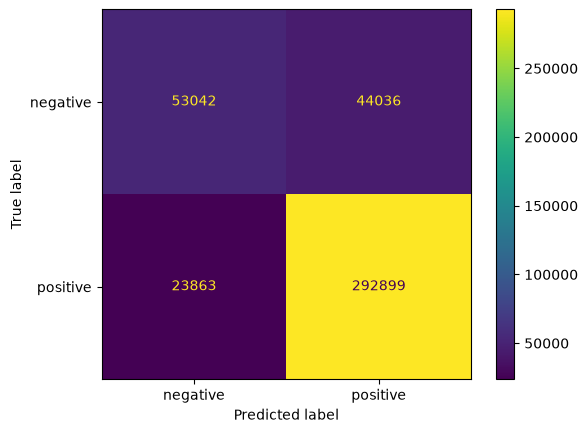

In [53]:
#ACC=TP/(TP+FP)
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix,accuracy_score,ConfusionMatrixDisplay
y_pred=df['compound'].apply(lambda x: 1 if x>=0 else 0)
y_true=df['Rating'].apply(lambda x: 1 if x>=3 else 0)
print(f'Accuracy: {accuracy_score(y_true,y_pred)}')
cm=confusion_matrix(y_true,y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['negative','positive'])
disp.plot()
plt.show()

# EDA and Data Preprocessing

1. Replace   null values in Brand Name with "Unknown" value
2. Find distribution of Rating (plot histogram)
3. Recode Rating  value into Sentiment (Rating >=3 - positive sentiment (1) , Rating  < 3 - negative (0))

In [8]:
df['Brand Name']=df['Brand Name'].fillna('Unknown').astype(str)
df['Reviews']=df['Reviews'].fillna('').astype(str)

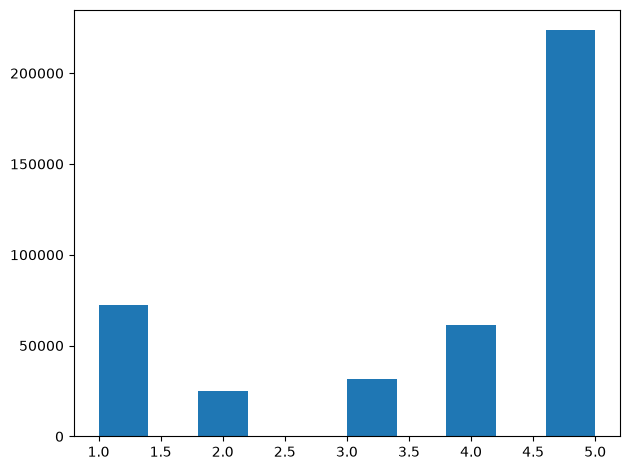

In [9]:
import matplotlib.pyplot as plt
plt.hist(df['Rating'])
plt.tight_layout()
plt.show()

In [10]:
df['RatingGrouped']=df['Rating'].apply(lambda x: 1 if x>=3 else 0)
df[['Rating','RatingGrouped']].head(10)

,Rating,RatingGrouped
0,5,1
1,4,1
2,5,1
3,4,1
4,4,1
5,1,0
6,2,0
7,2,0
8,5,1
9,3,1


# Text preprocessing
1. Change the words into its root words using spacy
2. Remove stopwords (optional)

| Komponent       | Co robi w NLP                                                       | Co dopisuje                            |
| --------------- | ------------------------------------------------------------------- | -------------------------------------- |
| tokenizer       | Dzieli tekst na tokeny (słowa, znaki)                               | Doc z tokenami spacy                   |
| tok2vec         | Tworzy wewnętrzne reprezentacje wektorowe dla kolejnych komponentów | współdzielone wektory cadetx           |
| tagger          | Przypisuje części mowy (rzeczownik, czasownik)                      | token.tag, token.pos spacy             |
| attribute_ruler | Reguły i wyjątki dla atrybutów tokenów                              | poprawki pos, lemma spacy              |
| lemmatizer      | Sprowadza słowa do formy podstawowej (reguły i słowniki)            | token.lemma_ spacy                     |
| parser          | Analiza zależności składniowych, granice zdań                       | token.dep, token.head, doc.sents spacy |
| ner             | Rozpoznaje encje nazwane (osoby, firmy, miejsca)                    | doc.ents spacy.pythonhumanities        |

In [11]:
import spacy
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

df['Lemats']=[
   ' '.join([token.lemma_.lower() for token in doc if token.is_alpha and not token.is_stop])
    for doc in nlp.pipe(df['Reviews'].astype(str).values, batch_size=500)
]

In [12]:
df.to_csv("Amazon_Unlocked_Mobile_after_spacy.csv", index=False)

# Tokenizing



Use Tokenizer to tokenize text

Replace value of oov_token is set to be ‘OOV’. That means any unknown words will be replaced by oov_token.

In [15]:
words=df['Lemats'].str.split().explode()
all_words=words.value_counts(normalize=True)
shares=all_words.cumsum()

In [26]:
shares

Lemats
phone              0.065889
work               0.083027
good               0.099107
great              0.113496
buy                0.123384
                     ...   
somethng           0.999999
clang              1.000000
satasfie           1.000000
paidfor            1.000000
refurrefurbishe    1.000000
Name: proportion, Length: 52737, dtype: float64

In [38]:
from kneed import KneeLocator
import numpy as np

knee=KneeLocator(x=np.arange(1,len(shares)+1),y=shares.values,curve='concave',direction='increasing')
print(knee.knee,knee.knee_y)

3125 0.9429205816065798


In [40]:
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer=Tokenizer(num_words=knee.knee, oov_token='OOV')
tokenizer.fit_on_texts(df['Lemats'].values)
sequences=tokenizer.texts_to_sequences(df['Lemats'].values)

In [43]:
sequences[:2]

[[89,
  1394,
  51,
  2,
  157,
  2,
  318,
  171,
  225,
  299,
  7,
  80,
  345,
  417,
  967,
  82,
  29,
  171,
  76,
  54,
  950,
  3097,
  58,
  2,
  41,
  54,
  302],
 [32,
  2,
  32,
  1973,
  1,
  1,
  516,
  114,
  59,
  114,
  42,
  2,
  427,
  52,
  96,
  2085,
  1017,
  643,
  5,
  2,
  47]]

# Padding

Pad sequences to maximal length



In [45]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
lens=np.array([list(map(len,sequences))])
max_len=int(np.percentile(lens,95))
print(max_len)
X=pad_sequences(sequences,maxlen=max_len,padding='post')

64


# Model Creation


Model:

*   Embedding
*   LSTM (30 units)
*   Dense (2 layers, 2 x relu, last layer-  sigmoid)

Loss function: binary cross entropy , optimizer = 'adam'



Try to  build network like this:

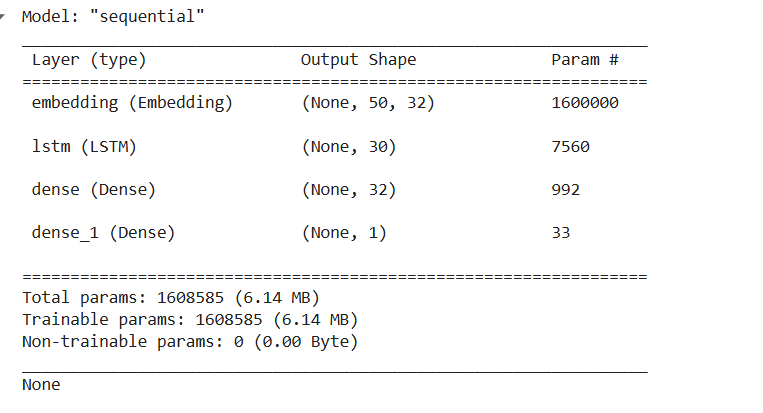

In [48]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense,Input
model=Sequential()
model.add(Input(shape=(max_len,)))
model.add(Embedding(input_dim=int(knee.knee)+1,output_dim=32))
model.add(LSTM(30))
model.add(Dense(32,activation='relu'))
model.add(Dense(1,activation='sigmoid'))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 64, 32)         │       100,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30)             │         7,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,617 (424.29 KB)

 Trainable params: 108,617 (424.29 KB)

 Non-trainable params: 0 (0.00 B)

# Split Data into Train and Test

Test: 30% of randomly chosen  observations.
Random Seed: 10

In [51]:
from sklearn.model_selection import train_test_split
y=df['RatingGrouped']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)
#
#
# fit model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history=model.fit(X_train,y_train,epochs=10,validation_data=(X_test,y_test),verbose=1)

Epoch 1/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 91s 10ms/step - accuracy: 0.8285 - loss: 0.4028 - val_accuracy: 0.9017 - val_loss: 0.2378
Epoch 2/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 92s 10ms/step - accuracy: 0.9103 - loss: 0.2211 - val_accuracy: 0.9098 - val_loss: 0.2179
Epoch 3/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 90s 10ms/step - accuracy: 0.9204 - loss: 0.1978 - val_accuracy: 0.9160 - val_loss: 0.2057
Epoch 4/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 95s 11ms/step - accuracy: 0.9279 - loss: 0.1817 - val_accuracy: 0.9218 - val_loss: 0.1997
Epoch 5/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 89s 10ms/step - accuracy: 0.9340 - loss: 0.1681 - val_accuracy: 0.9241 - val_loss: 0.1953
Epoch 6/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 91s 10ms/step - accuracy: 0.9395 - loss: 0.1559 - val_accuracy: 0.9279 - val_loss: 0.1917
Epoch 7/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 91s 10ms/step - accuracy: 0.9446 - loss: 0.1449 - val_accuracy: 0.9316 - val_loss: 0.1844
Epoch 8/10
9053/9053 ━━━━━━━━━━━━━━━━━━━━ 92s 10ms/step - accuracy: 0.9494 -

# Model Training

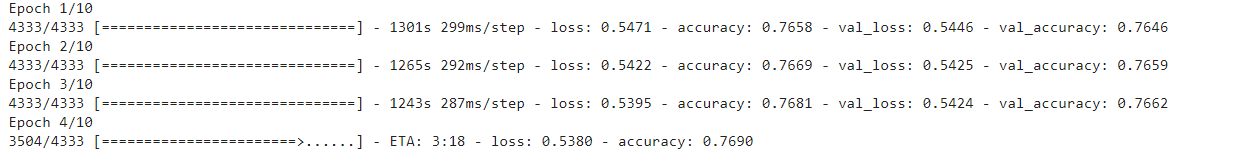

# Performance Metrics and Accuracy

Perform binary prediction on test data set

In [57]:
y_pred_test=(model.predict(X_test) > 0.5).astype(int)


3880/3880 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step


**Confusion Matrix**

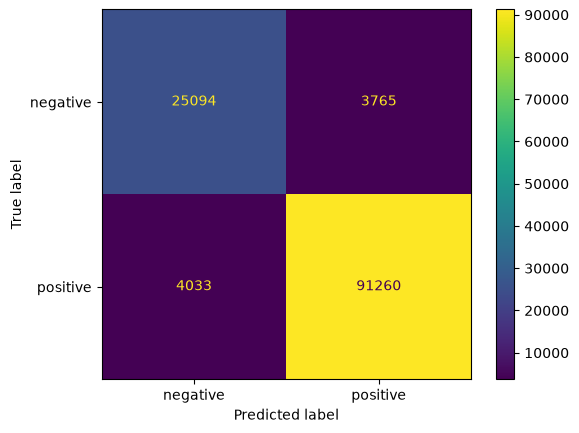

In [58]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

cm=confusion_matrix(y_pred_test,y_test)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['negative','positive'])
disp.plot()
plt.show()

**Accuracy Score**

In [59]:
from sklearn.metrics import accuracy_score

print('Accuracy Score:',accuracy_score(y_test,y_pred_test))

Accuracy Score: 0.9371898962562021
